# Lab 6: Localization (odometry)

Fayozbek Yusupov, ID 240061

The robot drives the "61" from Lab 1 with motors and timers. A parallel task counts the odometry with the formulas from the lecture (the blocks from `Localization_demo.qrs`) and writes `x,y,time` to a file in a loop with a 5 ms timer. The simulator and the real robot run the same blocks; the differences are the wheel radius `r` and the base `B` of each robot (r = 0.0375 m and B = 0.194 m on the real robot), the turn timers (550 ms and 850 ms on the real robot instead of 1000 ms and 1500 ms, because its motors are faster), the file name, and the marker, which exists only in the simulator.

Upload `odometry_data_sim.txt` and `odometry_data_real.txt` in the next cell.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select BOTH txt files

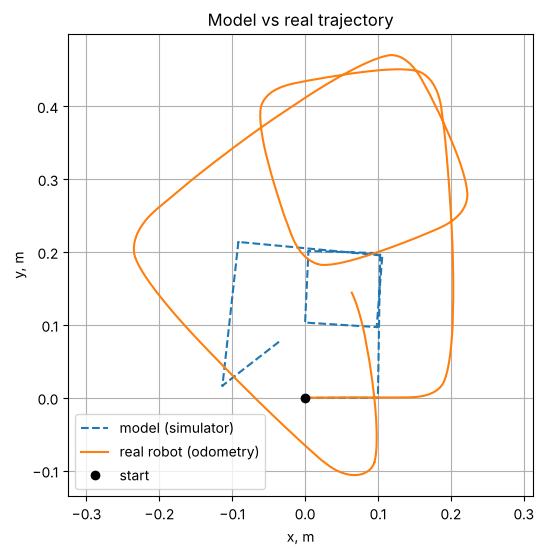

In [2]:
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

# 1. Trajectories on one plot
plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

In the simulator the robot drew the 61. In the plot it is upside down, because x is the direction the robot faced at the start. The real robot drew a bigger 61 with bent lines: it drives faster, its corners are a few degrees more than 90, and the straight pieces bend to the left.

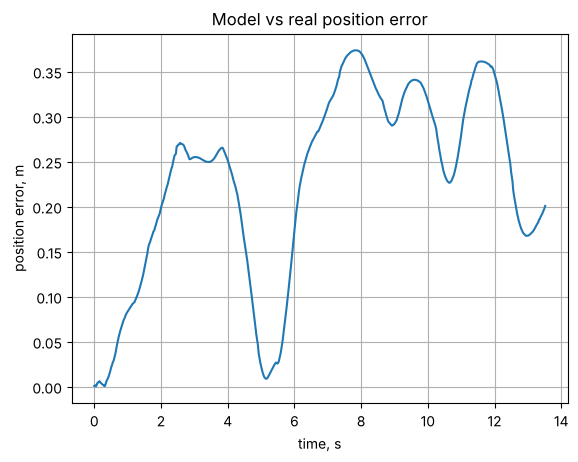

Final odometry error (sim vs real): 0.2 m
Max error: 0.4 m


In [3]:
# 2. Error over time (simulator resampled onto the real-robot timestamps)
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.1f} m')
print(f'Max error: {err.max():.1f} m')

## Conclusions

The real trajectory diverges from the model from the first piece: the real robot drives much faster (its path is 2.7 m against 1.2 m in the simulator), so its 61 is about twice as big, and its corners are 93–100° instead of 90° (142° instead of 135° for the last one). With the simulator timers (1000 ms per turn) the real robot turned far more than 90° and made loops, so on the real robot I shortened the turns to 550 ms and 850 ms. This is the "unequal wheels / motors" error from the lecture: the real motors are faster than the simulated ones, and the right motor is faster than the left one (my Week 5 k_e: 0.658 against 0.714), so even the straight pieces bend to the left. Because heading error dominates, the few extra degrees at every corner add up to about 50° by the end, and together with the bigger size this gives a final error of 0.2 m and a max error of 0.4 m. On my first run (1000 ms turns) I also measured the end point with a tape: the odometry was 0.29 m away from the real point, most likely because of wheel slip in the fast turns. The robot does not know it is wrong, because it only counts wheel rotations and slip is invisible to the encoders.